In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter
from lifelines.statistics import multivariate_logrank_test

df = pd.read_csv("../data/processed/telco_clean.csv")

# The 11 brand-new customers have tenure 0: no observed time yet, and none churned.
surv = df[df["tenure"] > 0].copy()
print(len(df), "->", len(surv))

T = surv["tenure"]   # duration: months observed
E = surv["Churn"]    # event: 1 = churned, 0 = censored (still active)

7043 -> 7032


In [2]:
kmf = KaplanMeierFitter()
kmf.fit(T, event_observed=E, label="All customers")

print("median survival time:", kmf.median_survival_time_)
print(kmf.predict([12, 24, 48, 72]).round(3))

median survival time: inf
12    0.843
24    0.789
48    0.709
72    0.593
Name: All customers, dtype: float64


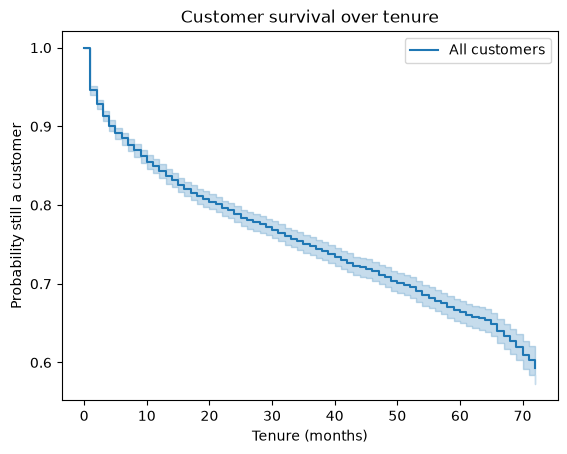

In [3]:
kmf.plot_survival_function()
plt.title("Customer survival over tenure")
plt.xlabel("Tenure (months)")
plt.ylabel("Probability still a customer")
plt.show()

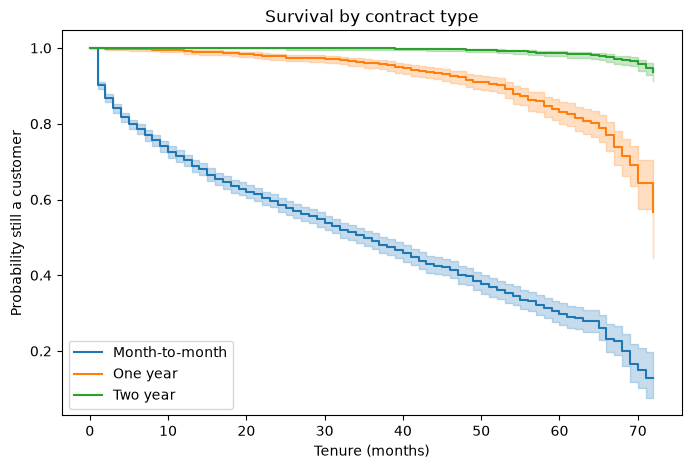

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
for name, group in surv.groupby("Contract"):
    km = KaplanMeierFitter()
    km.fit(group["tenure"], event_observed=group["Churn"], label=name)
    km.plot_survival_function(ax=ax)
ax.set_title("Survival by contract type")
ax.set_xlabel("Tenure (months)")
ax.set_ylabel("Probability still a customer")
plt.show()

In [5]:
result = multivariate_logrank_test(surv["tenure"], surv["Contract"], surv["Churn"])
print("log-rank p-value:", result.p_value)

log-rank p-value: 0.0
